# 01 · EDA and data cleaning

> **Simulated data.** Every row in this notebook comes from `pulso_exp.simulate` with a fixed seed.
> Pulso is a fictional company; nothing here describes real merchants, customers or results.

**Goal:** understand the four tables the experiment and the ETA model are built on, check data quality,
and make every cleaning decision explicit (what, how many rows, why) before any analysis touches the data.

The simulator deliberately plants problems a real pipeline would have: duplicated ingestion rows,
bot/integration-test merchants, amounts entered ×100, deliveries stuck for hours, and missing values.
A good EDA should find all of them *without* peeking at the generator.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pulso_exp.clean import CleaningReport, clean_orders, clean_sessions, find_bot_merchants
from pulso_exp.plotting import INK_SECONDARY, SERIES, apply_style
from pulso_exp.simulate import FUNNEL_STEPS, SimConfig, simulate

apply_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

cfg = SimConfig()  # seed=42, 60k merchants, 28-day pre-period + 28-day experiment
data = simulate(cfg)
pd.DataFrame(
    {
        name: [len(getattr(data, name)), getattr(data, name).shape[1]]
        for name in ("merchants", "sessions", "orders", "events")
    },
    index=["rows", "columns"],
)

,merchants,sessions,orders,events
rows,60015,182684,56071,573792
columns,5,9,25,5


## 1 · Tables and grain

| table | grain | key | notes |
|---|---|---|---|
| `merchants` | one merchant | `merchant_id` | category, city, experiment `variant` (hash bucketing on `merchant_id`) |
| `sessions` | one checkout session | `session_id` | `period` = `pre` (28 days, everyone sees control) or `experiment`; furthest `funnel_step` reached |
| `orders` | one order from a paid session | `order_id` | Pulso `Order` entity: status, `amount_cents` (MXN), pickup/dropoff, pulser, delivery time |
| `events` | one domain event | — | `checkout.viewed`, `payment.authorized`, `pulser.assigned`, `refund.issued`, … |

In [2]:
data.sessions.head(3)

,session_id,merchant_id,variant,period,started_at,device,funnel_step,payment_failed,page_load_ms
0,d868a080-de6a-4c84-8e76-4f950156cc2f,8a481f39-eef2-43ae-a404-73ca75035854,treatment,pre,2026-03-02 00:00:44,ios,paid,False,526.0
1,a32ec514-e525-4ca6-b6ae-55a579de595e,6388e9ef-4380-4661-a7a1-6a3c204beca1,control,pre,2026-03-02 00:06:22,web,paid,False,644.0
2,618e2997-8e07-4def-a251-a80cacdf71d3,86141ded-d642-4438-831e-e3698aaf30c4,treatment,pre,2026-03-02 00:16:17,NaN,paid,False,889.0


In [3]:
data.orders[
    [
        "order_id",
        "merchant_id",
        "status",
        "created_at",
        "amount_cents",
        "currency",
        "city",
        "category",
        "vehicle",
        "pulser_rating",
        "pulser_active_tasks",
        "raining",
        "eta_minutes",
        "delivery_minutes",
    ]
].head(3)

,order_id,merchant_id,status,created_at,amount_cents,currency,city,category,vehicle,pulser_rating,pulser_active_tasks,raining,eta_minutes,delivery_minutes
0,20aaf22f-28ce-4805-9490-ea873a67efc9,8a481f39-eef2-43ae-a404-73ca75035854,DELIVERED,2026-03-02 00:08:39,47580,MXN,CDMX,grocery,CAR,4.83,0,False,73.0,93.0
1,608fc79d-83ad-45a5-9a8d-a317ffd02dfe,6388e9ef-4380-4661-a7a1-6a3c204beca1,DELIVERED,2026-03-02 00:13:16,8142,MXN,Puebla,restaurant,MOTO,4.53,2,False,39.0,45.5
2,95def451-71f5-4ac0-92d7-cdfbbe3d352c,86141ded-d642-4438-831e-e3698aaf30c4,DELIVERED,2026-03-02 00:19:53,18071,MXN,Monterrey,restaurant,BIKE,3.92,1,True,17.0,42.5


## 2 · Data quality checks

Generic checks first — key uniqueness, null rates, value ranges — then targeted looks at whatever they flag.

In [4]:
def quality_summary(df: pd.DataFrame, key: str) -> pd.Series:
    nulls = df.isna().mean()
    return pd.Series(
        {
            "rows": len(df),
            "duplicate keys": int(df[key].duplicated().sum()),
            "fully duplicated rows": int(df.duplicated().sum()),
            "columns with nulls": ", ".join(f"{c} ({v:.1%})" for c, v in nulls[nulls > 0].items())
            or "-",
        }
    )


pd.DataFrame(
    {
        "merchants": quality_summary(data.merchants, "merchant_id"),
        "sessions": quality_summary(data.sessions, "session_id"),
        "orders": quality_summary(data.orders, "order_id"),
    }
).T

,rows,duplicate keys,fully duplicated rows,columns with nulls
merchants,60015,0,0,-
sessions,182684,937,937,"device (2.0%), page_load_ms (3.1%)"
orders,56071,0,0,"pulser_id (3.2%), vehicle (3.2%), pulser_ratin..."


In [5]:
o = data.orders
range_checks = pd.Series(
    {
        "amount_cents <= 0": int((o["amount_cents"] <= 0).sum()),
        "coordinates outside Mexico bbox": int(
            (~o["pickup_lat"].between(14, 33) | ~o["pickup_lng"].between(-118, -86)).sum()
        ),
        "delivery_minutes < 0": int((o["delivery_minutes"] < 0).sum()),
        "delivery_minutes > 240 (4 h)": int((o["delivery_minutes"] > 240).sum()),
        "pulser_rating outside [0, 5]": int(
            (~o["pulser_rating"].between(0, 5) & o["pulser_rating"].notna()).sum()
        ),
        "page_load_ms >= 30 000 (timeout)": int((data.sessions["page_load_ms"] >= 30_000).sum()),
        "orders whose session_id is not a paid session": int(
            (
                ~o["session_id"].isin(
                    data.sessions.loc[data.sessions["funnel_step"] == "paid", "session_id"]
                )
            ).sum()
        ),
    }
)
range_checks.to_frame("rows")

,rows
amount_cents <= 0,0
coordinates outside Mexico bbox,0
delivery_minutes < 0,0
delivery_minutes > 240 (4 h),153
"pulser_rating outside [0, 5]",0
page_load_ms >= 30 000 (timeout),175
orders whose session_id is not a paid session,0


**Findings so far**

* `sessions` has duplicated `session_id`s and they are *full-row* duplicates → an ingestion retry, not two
  sessions sharing an id. Safe to drop.
* `device` and `page_load_ms` have a few percent missing; `pulser_rating` is missing on some orders.
* Nothing is out of physical range, but there is a long delivery tail (> 4 h) and some client timeouts.
* Referential integrity holds: every order comes from a paid session.

### 2.1 · The event log agrees with the session table

The funnel can be rebuilt from raw events; if it disagrees with the session table, one of them is broken.

In [6]:
ev = data.events["event_name"].value_counts()
dedup = data.sessions.drop_duplicates("session_id")
step_idx = dedup["funnel_step"].map({s: i for i, s in enumerate(FUNNEL_STEPS)})
pd.DataFrame(
    {
        "from events": [
            ev["checkout.viewed"],
            ev["checkout.details_completed"],
            ev["payment.submitted"],
            ev["payment.authorized"],
        ],
        "from sessions": [(step_idx >= i).sum() for i in range(4)],
    },
    index=FUNNEL_STEPS,
)

,from events,from sessions
checkout_view,181747,181747
details,103887,103887
payment_submitted,60247,60247
paid,56071,56071


### 2.2 · Sessions per merchant: a second population hiding in the tail

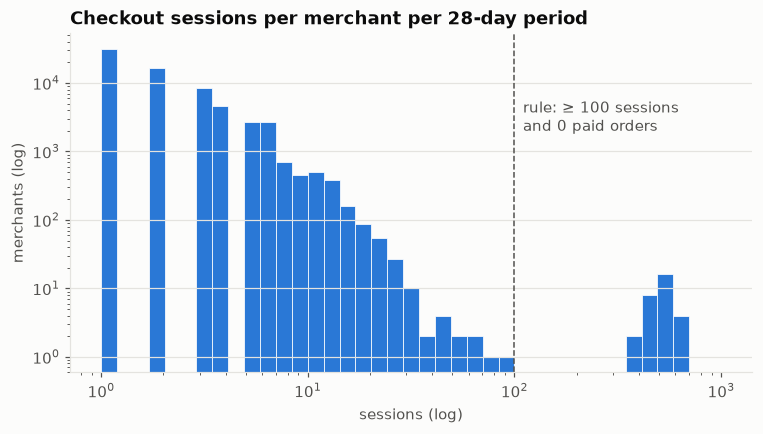

,merchant_id,period,sessions,paid
43085,a03f3304-f75e-4ecc-97f8-ce616df9ed93,pre,690,0
43084,a03f3304-f75e-4ecc-97f8-ce616df9ed93,experiment,673,0
5117,13015c70-ccf1-4536-98c2-f309fbf04ed9,experiment,643,0
5118,13015c70-ccf1-4536-98c2-f309fbf04ed9,pre,609,0
20220,4be64c69-a65e-4ee7-9d34-53af4f15f008,pre,578,0


In [7]:
per_merchant = (
    data.sessions.drop_duplicates("session_id")
    .groupby(["merchant_id", "period"])
    .agg(sessions=("session_id", "size"), paid=("funnel_step", lambda s: (s == "paid").sum()))
    .reset_index()
)

fig, ax = plt.subplots()
bins = np.logspace(0, 3, 40)
ax.hist(per_merchant["sessions"], bins=bins, color=SERIES[0], edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
ax.set_yscale("log")
ax.axvline(100, color=INK_SECONDARY, linestyle="--", linewidth=1)
ax.annotate("rule: ≥ 100 sessions\nand 0 paid orders", xy=(110, 2000), color=INK_SECONDARY)
ax.set_title("Checkout sessions per merchant per 28-day period")
ax.set_xlabel("sessions (log)")
ax.set_ylabel("merchants (log)")
plt.show()

per_merchant.sort_values("sessions", ascending=False).head(5)

A clean gap separates ordinary merchants (the heaviest real merchants stay below 100 sessions a period) from a cluster with
**hundreds of sessions and zero paid orders**, all on `web`. That is integration/bot traffic. Because it is assigned to
variants like any merchant, leaving it in would dilute conversion and inflate session counts in whichever arm it lands.

**Rule:** a merchant with ≥ 100 checkout sessions in a period *and* no paid order is excluded from every analysis.
The rule is defined on behaviour that the treatment cannot cause (a bot does not convert in either arm).

### 2.3 · Order amounts: a bump two orders of magnitude to the right

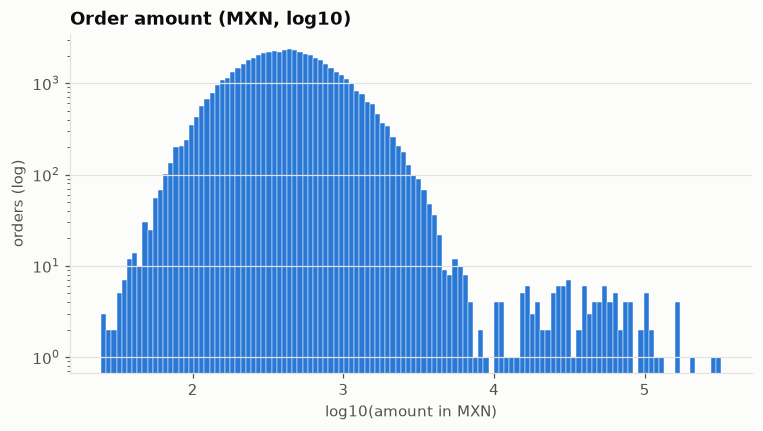

,size,median,category_median
category,,,
flowers,7,6394000.0,59415.0
grocery,30,5862950.0,45811.0
pharmacy,24,3354000.0,29904.5
restaurant,30,2624150.0,28044.0
retail,11,9962700.0,90755.0


In [8]:
fig, ax = plt.subplots()
log_amount = np.log10(o["amount_cents"] / 100)
ax.hist(log_amount, bins=120, color=SERIES[0], edgecolor="white", linewidth=0.3)
ax.set_yscale("log")
ax.set_title("Order amount (MXN, log10)")
ax.set_xlabel("log10(amount in MXN)")
ax.set_ylabel("orders (log)")
plt.show()

typo_like = o[
    o["amount_cents"] > 50 * o["category"].map(o.groupby("category")["amount_cents"].median())
]
typo_like.groupby("category")["amount_cents"].agg(["size", "median"]).assign(
    category_median=o.groupby("category")["amount_cents"].median()
)

The main mass is a log-normal around a few hundred MXN; a separate bump sits exactly ~100× higher, with the
same per-category shape. That is the signature of an amount typed in cents into a pesos field (or vice versa),
not of genuinely large baskets — a real large-basket tail would be smooth.

**Rule:** amounts above 50× the category median are divided by 100 and flagged (`amount_fixed`). Risk: a genuine
50× basket would be wrongly shrunk. At this threshold, the clean log-normal places essentially no mass there,
so the expected false-fix count is ~0; the flag keeps the decision auditable.

### 2.4 · Delivery time tail

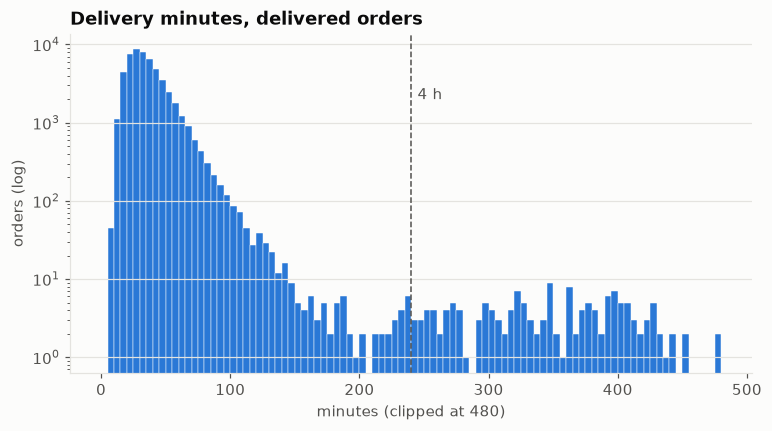

count    53695.0
mean        37.4
std         24.0
min          6.0
50%         32.9
90%         57.5
99%        101.2
99.9%      377.5
max        522.6
Name: delivery_minutes, dtype: float64

In [9]:
delivered = o[o["status"] == "DELIVERED"]
fig, ax = plt.subplots()
ax.hist(
    delivered["delivery_minutes"].clip(upper=480),
    bins=np.arange(0, 485, 5),
    color=SERIES[0],
    edgecolor="white",
    linewidth=0.3,
)
ax.set_yscale("log")
ax.axvline(240, color=INK_SECONDARY, linestyle="--", linewidth=1)
ax.annotate("4 h", xy=(245, 2000), color=INK_SECONDARY)
ax.set_title("Delivery minutes, delivered orders")
ax.set_xlabel("minutes (clipped at 480)")
ax.set_ylabel("orders (log)")
plt.show()
delivered["delivery_minutes"].describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(1)

Past ~2.5 h the distribution stops decaying and turns into a flat plateau: those are orders that got
*stuck* (pulser phone dead, order not closed in the app). The 4 h cut is deliberately conservative — a few stuck
orders sit between 2.5 h and 4 h and stay in, which costs a little model accuracy but never removes a genuinely
slow delivery. They are real operational events — keep them for ops
metrics — but they are not information about how long a delivery takes, so they are excluded when training the
ETA model (notebook 03).

## 3 · Cleaning decisions

All rules live in `pulso_exp.clean` (unit-tested) and produce a report, so the notebook shows exactly what happened.

In [10]:
report = CleaningReport()
sessions = clean_sessions(data.sessions, report)
bots = find_bot_merchants(data.sessions)
orders = clean_orders(data.orders, bot_merchants=bots, report=report)
report.to_frame()

,table,rule,rows_affected,action
0,sessions,exact duplicate session_id,937,dropped
1,sessions,"bot merchants (>= 100 sessions/period, 0 paid)...",15728,dropped (merchant excluded from every analysis)
2,sessions,missing device,3375,kept as 'unknown'
3,sessions,missing page_load_ms,5078,kept as NaN (excluded from latency guardrail o...
4,sessions,page_load_ms >= 30 s (client timeout),157,"kept: real user pain, the p95 guardrail should..."
5,orders,amount_cents > 50x category median,102,divided by 100 (x100 entry typo)
6,orders,delivery_minutes > 240,153,flagged 'stuck'; excluded from ETA model train...
7,orders,missing pulser_rating on assigned orders,2130,kept as NaN (new pulsers); the model handles m...
8,orders,delivery_minutes missing (not DELIVERED),2376,expected: cancelled/failed orders have no deli...


What is **not** done, on purpose:

* **No imputation of `page_load_ms`.** Missingness is unrelated to arm here (checked below); the latency guardrail is a
  percentile, so dropping NaNs is honest while imputing a median would shrink the tail we care about.
* **Timeouts are kept.** A 30 s page load is the worst user experience there is; removing it would flatter the p95.
* **`pulser_rating` stays NaN.** Missing means "new pulser", which is itself informative; gradient boosting handles it natively.

In [11]:
exp = sessions[sessions["period"] == "experiment"]
exp.groupby("variant").agg(
    sessions=("session_id", "size"),
    missing_latency=("page_load_ms", lambda s: s.isna().mean()),
    unknown_device=("device", lambda s: (s == "unknown").mean()),
).style.format({"missing_latency": "{:.2%}", "unknown_device": "{:.2%}", "sessions": "{:,}"})

,sessions,missing_latency,unknown_device
variant,,,
control,"41,767",3.09%,2.03%
treatment,"41,433",2.95%,2.10%


## 4 · Distributions after cleaning

### 4.1 · Checkout funnel (pre-period, everyone on the current checkout)

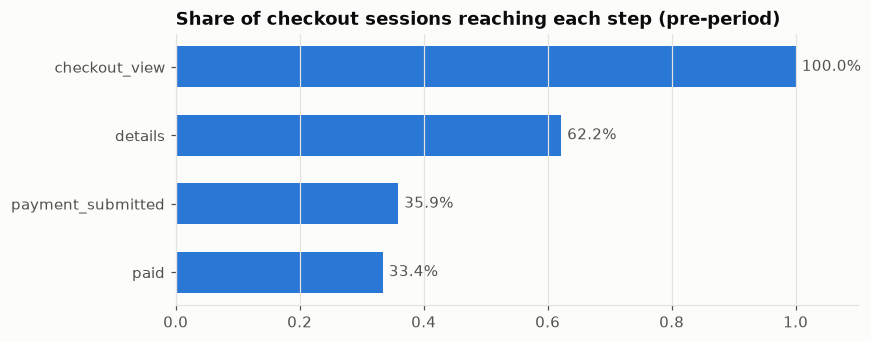

,step-to-step conversion
details,62.2%
payment_submitted,57.7%
paid,93.1%


In [12]:
pre = sessions[sessions["period"] == "pre"]
reached = pd.Series(
    {
        step: (pre["funnel_step"].map({s: i for i, s in enumerate(FUNNEL_STEPS)}) >= i).mean()
        for i, step in enumerate(FUNNEL_STEPS)
    }
)
fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.barh(reached.index[::-1], reached.to_numpy()[::-1], color=SERIES[0], height=0.6)
ax.bar_label(
    bars, labels=[f"{v:.1%}" for v in reached.to_numpy()[::-1]], padding=4, color=INK_SECONDARY
)
ax.set_xlim(0, 1.1)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title("Share of checkout sessions reaching each step (pre-period)")
plt.show()
step_conversion = (reached / reached.shift(1)).dropna().rename("step-to-step conversion")
step_conversion.to_frame().style.format("{:.1%}")

Two steps leak about equally: ~4 in 10 sessions never get past the first screen, and ~4 in 10 of those who fill
in details never submit payment. The **one-page checkout** tested in notebook 02 merges the details and payment
screens, so it targets the second leak — that step is where we expect the effect to show up.

### 4.2 · When do merchants check out?

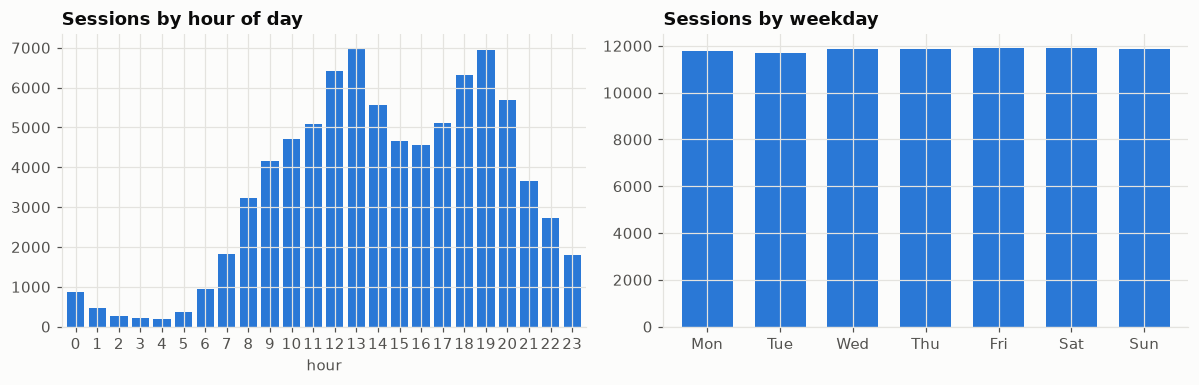

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
pre["started_at"].dt.hour.value_counts().sort_index().plot.bar(
    ax=axes[0], color=SERIES[0], width=0.8
)
axes[0].set_title("Sessions by hour of day")
axes[0].set_xlabel("hour")
dow = pre["started_at"].dt.day_of_week.value_counts().sort_index()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow.plot.bar(ax=axes[1], color=SERIES[0], width=0.7)
axes[1].set_title("Sessions by weekday")
axes[1].set_xlabel("")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

Lunch and dinner peaks; weekdays are flat (the simulator has no weekly seasonality — a real dataset would, which is why the
experiment still runs for whole weeks).

### 4.3 · Delivery time by vehicle and distance

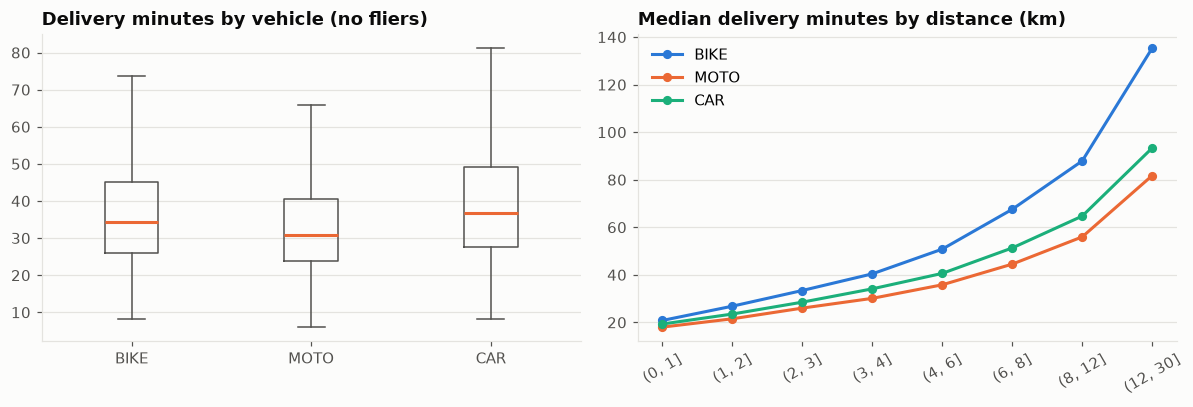

In [14]:
d = orders[(orders["status"] == "DELIVERED") & ~orders["stuck"]].copy()
d["distance_km"] = np.hypot(
    (d["dropoff_lat"] - d["pickup_lat"]) * 111,
    (d["dropoff_lng"] - d["pickup_lng"]) * 111 * np.cos(np.radians(d["pickup_lat"])),
)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
vehicles = ["BIKE", "MOTO", "CAR"]
axes[0].boxplot(
    [d.loc[d["vehicle"] == v, "delivery_minutes"] for v in vehicles],
    tick_labels=vehicles,
    showfliers=False,
    medianprops={"color": SERIES[1], "linewidth": 2},
    boxprops={"color": INK_SECONDARY},
    whiskerprops={"color": INK_SECONDARY},
    capprops={"color": INK_SECONDARY},
)
axes[0].set_title("Delivery minutes by vehicle (no fliers)")
d["distance_bin"] = pd.cut(d["distance_km"], [0, 1, 2, 3, 4, 6, 8, 12, 30])
med = (
    d.groupby(["distance_bin", "vehicle"], observed=True)["delivery_minutes"]
    .median()
    .unstack()[vehicles]
)
for i, v in enumerate(vehicles):
    axes[1].plot(range(len(med)), med[v], marker="o", markersize=5, color=SERIES[i], label=v)
axes[1].set_xticks(range(len(med)), [str(b) for b in med.index], rotation=30)
axes[1].set_title("Median delivery minutes by distance (km)")
axes[1].legend()
plt.tight_layout()
plt.show()

Distance dominates, but its slope depends on the vehicle: bikes keep up on trips under ~2 km and fall far behind
beyond 4 km, while motos are fastest at every distance. That vehicle × distance interaction is something a tree model
picks up for free and the legacy `10 + 4·km` quote ignores.

### 4.4 · Pre-period balance between arms (A/A sanity check)

The pre-period was served the same checkout to everyone, so the future arms must look identical there.
A difference here would mean the bucketing is correlated with merchant behaviour.

In [15]:
pre_m = (
    pre.groupby(["merchant_id", "variant"])
    .agg(sessions=("session_id", "size"), converted=("funnel_step", lambda s: (s == "paid").any()))
    .reset_index()
)
pre_m.groupby("variant").agg(
    merchants=("merchant_id", "size"),
    sessions_per_merchant=("sessions", "mean"),
    conversion=("converted", "mean"),
).style.format({"sessions_per_merchant": "{:.3f}", "conversion": "{:.2%}", "merchants": "{:,}"})

,merchants,sessions_per_merchant,conversion
variant,,,
control,"17,243",2.413,51.64%
treatment,"17,115",2.408,51.97%


## 5 · Takeaways

1. **Five data problems found and handled:** duplicate sessions (dropped), 15 bot merchants (excluded everywhere),
   ×100 amount typos (fixed + flagged), stuck deliveries > 4 h (flagged, excluded from model training), and
   missing device/latency/rating values (kept, each with a stated reason).
2. **The funnel leaks most at details → payment**, the step the one-page checkout targets.
3. **Arms are balanced before the test**, so differences during the experiment can be attributed to the treatment.

The cleaned tables are rebuilt the same way at the top of notebooks 02 and 03 (`clean_sessions` / `clean_orders`),
so there is a single definition of "clean".